# Tarea 2 — Inteligencia Artificial



- Integrantes: Andrés Hormazabal, Héctor Vines.
- Profesor: Johan Fuentes. 
- Ayudantes: Dante Libiot, Miguel Pereira, Matias Vasquez.
- URL del dataset utilizado para la pregunta 1: https://www.kaggle.com/datasets/saichaitanyareddyai/spotify-tracks-dataset-audio-features

# 0. Configuración inicial

La Pregunta 1 utiliza el archivo de Spotify incluido en el repositorio.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import display
from pandas.plotting import scatter_matrix
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler, add_dummy_feature
from sklearn.feature_selection import mutual_info_classif
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score, confusion_matrix, f1_score, precision_score, recall_score, roc_auc_score,
)

In [2]:
path_spotify = Path("data/raw/spotify-tracks-dataset-detailed.csv")
if not path_spotify.is_file():
    path_spotify = Path("notebooks") / path_spotify
df_spotify = pd.read_csv(path_spotify)
print(f"Spotify: {len(df_spotify):,} filas")

Spotify: 114,000 filas


---
# PREGUNTA 1 (30 puntos) — Aprendizaje supervisado

**Enunciado:** aplicar regresión lineal (variable continua $Y_1$) y regresión logística (variable binaria $Y_2$) sobre un dataset de ≥20.000 filas y ≥12 columnas, con las mismas 10 variables predictoras $X_1,\dots,X_{10}$ y partición 70% / 15% / 15%. Para cada tarea se entrenan tres versiones (10, 5 y 3 variables más relevantes, seleccionadas solo con datos de entrenamiento), se comparan en entrenamiento y validación, y solo las dos mejores se evalúan en prueba. Finalmente se analiza la influencia del número de variables en el desempeño y la generalización (overfitting / underfitting).

**Contenido:**
- 1.0 Dataset y variables
- 1.1 Selección de variables objetivo y predictoras
- 1.2 División del dataset
- **1.A** Regresión lineal ($Y_1$): selección de variables, entrenamiento, comparación, evaluación en prueba
- **1.B** Regresión logística ($Y_2$): selección de variables, entrenamiento, comparación, evaluación en prueba
- **1.C** Análisis final de la Pregunta 1


## Parte 1 — Algoritmos de aprendizaje supervizado

El dataset elegido fue el `spotify-tracks-dataset-detailed.csv` por la cantidad de filas y columnas que tiene, ya que cumple con los requerimientos de la tarea. Además, el área de la música es interesante para nosotros, y poder usar un dataset de este dominio, permitirá ver cómo se ajusta un proceso de Machine Learning para este tipo de datos.


### 1.0 Dataset y variables

| # | Columna | Descripción | Tipo |
|---|---|---|---|
| 0 | track_id | Identificador único de la pista en Spotify | Categórica (texto) |
| 1 | artists | Artista(s) que interpretan la pista, separados por ; | Categórica (texto) |
| 2 | album_name | Nombre del álbum en que aparece la pista | Categórica (texto) |
| 3 | track_name | Nombre de la pista | Categórica (texto) |
| 4 | popularity | Popularidad de la pista (0 a 100), según reproducciones recientes | Numérica discreta |
| 5 | duration_ms | Duración de la pista en milisegundos | Numérica continua |
| 6 | explicit | Indica si la pista tiene contenido explícito | Binaria (booleana) |
| 7 | danceability | Qué tan bailable es la pista (0.0 a 1.0) | Numérica continua |
| 8 | energy | Intensidad y actividad percibida de la pista (0.0 a 1.0) | Numérica continua |
| 9 | key | Tonalidad de la pista (0 = Do, 1 = Do#, ..., 11 = Si) | Categórica (codificada numéricamente) |
| 10 | loudness | Volumen promedio de la pista en decibelios (dB) | Numérica continua |
| 11 | mode | Modalidad de la pista (1 = mayor, 0 = menor) | Binaria |
| 12 | speechiness | Presencia de palabras habladas en la pista (0.0 a 1.0) | Numérica continua |
| 13 | acousticness | Confianza de que la pista sea acústica (0.0 a 1.0) | Numérica continua |
| 14 | instrumentalness | Probabilidad de que la pista no contenga voz (0.0 a 1.0) | Numérica continua |
| 15 | liveness | Probabilidad de que la pista sea una grabación en vivo (0.0 a 1.0) | Numérica continua |
| 16 | valence | Positividad musical transmitida por la pista (0.0 a 1.0) | Numérica continua |
| 17 | tempo | Tempo estimado de la pista en pulsos por minuto (BPM) | Numérica continua |
| 18 | time_signature | Compás estimado de la pista (pulsos por compás) | Numérica discreta |
| 19 | track_genre | Género musical asociado a la pista | Categórica (texto) |





Este es un problema de entrenamiento supervizado, dado que el modelo puede ser entrenado con ejemplos etiquetados.  

> La tarea 1 del modelo consistira en: dadas las características acústicas de una canción, se predice su `popularidad`. Se ocupara `regresión lineal` para realizar esta tarea y el momento de la predicción sera cuando tenga una cantidad no nula de reproducciones.

> La tarea 2 de este modelo será: dadas las mismas características ocupadas en el modelo anterior, se puede predecir si el contenido es `explícito`. Lo que se espera es que las características acústicas de una canción no esten relacionadas a si tiene un contenido explícito o no.


In [3]:

df_spotify.info()
df_spotify.describe()

#Conteno de nulos por columna 
print("\nConteo de nulos por columna:")
print(df_spotify.isnull().sum()[df_spotify.isnull().sum() > 0])

print("---------")
# Limpieza
print("Duplicados por track_id:", df_spotify['track_id'].duplicated().sum())
print("Filas completamente duplicadas:", df_spotify.duplicated().sum())

print("---------")

df_clean = df_spotify.drop_duplicates(subset='track_id', keep=('first')).copy()
print("Filas:", len(df_clean))
print("Duplicados restantes: ", df_clean['track_id'].duplicated().sum())

print("---------")

for c in ['tempo', 'duration_ms', 'danceability']:
    print(c, "ceros:", (df_clean[c] == 0).sum())


print("---------")
print("Antes:", len(df_clean))

mask_valid = (df_clean['tempo'] != 0) & (df_clean['danceability'] != 0) & (df_clean['duration_ms'] != 0) & (df_clean['popularity'] != 0)

df_clean = df_clean[mask_valid]

print("Después:", len(df_clean))


for c in ['tempo', 'duration_ms', 'danceability', 'popularity']:
    print(c, "ceros:", (df_clean[c] == 0).sum())


print("---------")

df_clean['explicit'] = df_clean['explicit'].astype(int)
print("Proporción explicit:", df_clean['explicit'].mean())


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 114000 entries, 0 to 113999
Data columns (total 20 columns):
 #   Column            Non-Null Count   Dtype  
---  ------            --------------   -----  
 0   track_id          114000 non-null  object 
 1   artists           113999 non-null  object 
 2   album_name        113999 non-null  object 
 3   track_name        113999 non-null  object 
 4   popularity        114000 non-null  int64  
 5   duration_ms       114000 non-null  int64  
 6   explicit          114000 non-null  bool   
 7   danceability      114000 non-null  float64
 8   energy            114000 non-null  float64
 9   key               114000 non-null  int64  
 10  loudness          114000 non-null  float64
 11  mode              114000 non-null  int64  
 12  speechiness       114000 non-null  float64
 13  acousticness      114000 non-null  float64
 14  instrumentalness  114000 non-null  float64
 15  liveness          114000 non-null  float64
 16  valence           11

In [4]:
df_clean.head()

,track_id,artists,album_name,track_name,popularity,duration_ms,explicit,danceability,energy,key,loudness,mode,speechiness,acousticness,instrumentalness,liveness,valence,tempo,time_signature,track_genre
0,5SuOikwiRyPMVoIQDJUgSV,Gen Hoshino,Comedy,Comedy,73,230666,0,0.676,0.4610,1,-6.746,0,0.1430,0.0322,0.000001,0.3580,0.715,87.917,4,acoustic
1,4qPNDBW1i3p13qLCt0Ki3A,Ben Woodward,Ghost (Acoustic),Ghost - Acoustic,55,149610,0,0.420,0.1660,1,-17.235,1,0.0763,0.9240,0.000006,0.1010,0.267,77.489,4,acoustic
2,1iJBSr7s7jYXzM8EGcbK5b,Ingrid Michaelson;ZAYN,To Begin Again,To Begin Again,57,210826,0,0.438,0.3590,0,-9.734,1,0.0557,0.2100,0.000000,0.1170,0.120,76.332,4,acoustic
3,6lfxq3CG4xtTiEg7opyCyx,Kina Grannis,Crazy Rich Asians (Original Motion Picture Sou...,Can't Help Falling In Love,71,201933,0,0.266,0.0596,0,-18.515,1,0.0363,0.9050,0.000071,0.1320,0.143,181.740,3,acoustic
4,5vjLSffimiIP26QG5WcN2K,Chord Overstreet,Hold On,Hold On,82,198853,0,0.618,0.4430,2,-9.681,1,0.0526,0.4690,0.000000,0.0829,0.167,119.949,4,acoustic


En un inicio, el dataset contaba con 114.000 filas. Una parte de ellas tenían valores duplicadas o nulos. Si se dejaban las filas duplicadas(misma canción en varios géneros), una copia podría ser asignada en el set de entrenamiento y otra en el de testeo, por lo que el modelo no generalizaría bien.


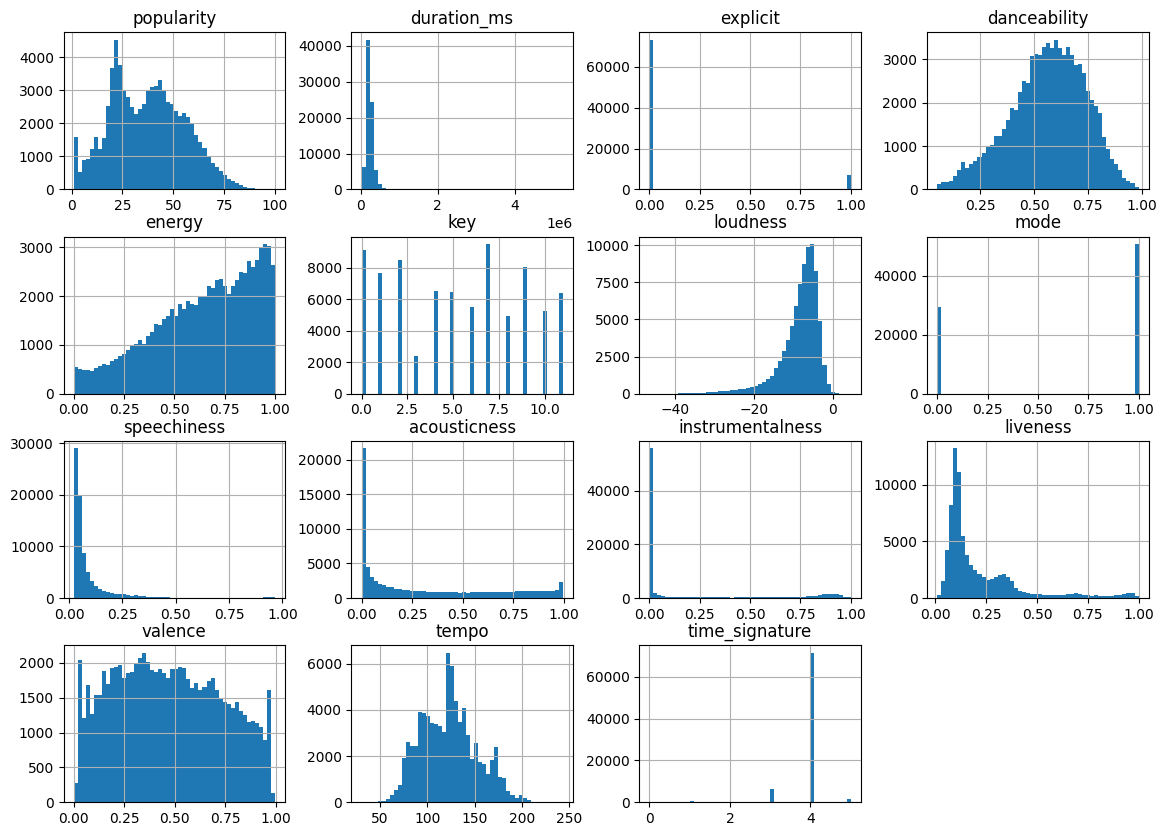

In [5]:

df_clean.hist(bins=50, figsize=(14,10))
plt.show()

### 1.1 Selección de variables objetivo (Y1, Y2) y predictoras (X1,...,X10)


> La variable continua $Y_1$ elegida es `popularity`.

Se eligio esta variable dado que la popularidad de una canción depende de factores que el dataset no tiene como numéricos (artista, campaña, inclusión en playlists). Y dentro del dataset, es la única variable que describe el alcance real que tuvo la canción.

Hay que mencionar que después de la limpieza de los datos, la media de `popularity` cambio de 33,19 a 37,10. Su desviación estandar cambio de 20,59 a 18,14 (varianza −22%).
 
> La variable discreta binaria $Y_2$ elegida es `explicit`.

Se eligio esta variable en particular porque dentro del dataset, esta es la única variable binaria.

Lo que se espera es que las características acústicas de una canción no estén relacionadas a si tiene un contenido explícito.

> Las 10 variables predictoras iniciales elegidas son : `duration_ms`,`danceability`,`energy`,`loudness`,`speechiness`,`acousticness`,`instrumentalness`,`liveness`,`tempo`,`valence`.

Se eligirieron estas variables dado que son de tipo numérica continua. Se excluyeron `key`, `mode`, `time_signature` dado que son variables categóricas. En el caso de *key*, es circular(después de un Si, viene un Do); *mode* y *time_signature* son etiquetas sin un orden. Todos los demás atributos se descartaron por ser texto o identificadores. 


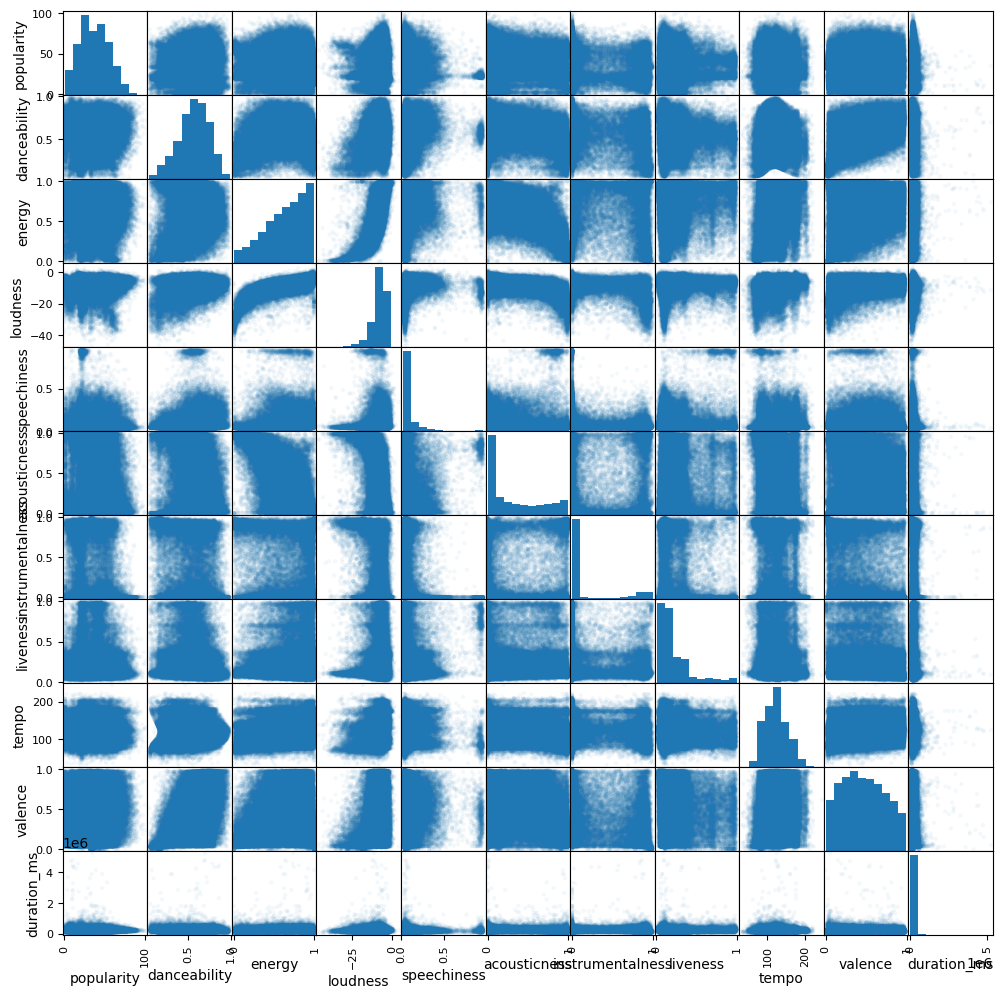

In [6]:


# Eleccion de variables predictorias
attributes = [
    'popularity',
    'danceability',
    'energy',
    'loudness',
    'speechiness',
    'acousticness',
    'instrumentalness',
    'liveness',
    'tempo',
    'valence',
    'duration_ms'
]
scatter_matrix(df_clean[attributes], figsize=(12, 12), alpha=0.05)
plt.show() 

### 1.2 División del dataset (70% entrenamiento / 15% validación / 15% prueba)

In [7]:
seed = 42
split_test = 0.15
split_val = 0.15

print( df_clean['explicit'].mean())

split_relative_val = split_val / (1 - split_test) # 0.15/(1 - 0.15) 
print(f"Proporción para el set de entrenamiento y validación: {split_relative_val}")

# 1. Apartar set de pruebas
temp, df_test  = train_test_split(df_clean, test_size=split_test, random_state=seed)

# 2. partir el resto 
df_train, df_val = train_test_split(temp, test_size=split_relative_val, random_state=seed)

n = len(df_clean)
for nombre, conj in [("train", df_train), ("val", df_val), ("test", df_test)]:
    print(f"{nombre:}: {len(conj):} filas  ({len(conj)/n})")
print(f"{'TOTAL' }: {len(df_train) + len(df_val) + len(df_test)} filas")


0.08651110556526079
Proporción para el set de entrenamiento y validación: 0.17647058823529413
train: 56098 filas  (0.7)
val: 12021 filas  (0.15)
test: 12021 filas  (0.15)
TOTAL: 80140 filas


`print( df_clean['explicit'].mean())` retorna el promedio de la columana **explicit**. El valor 0.08651110556526079 indica que un ~ 8.65% tienen contenido explícito. 




In [8]:
for nombre, conj in [("train", df_train), ("val", df_val), ("test", df_test)]:
    print(f"\n{nombre}: {conj['popularity'].mean()}")
    print(f"{nombre}: {conj['explicit'].mean()}")
    


train: 37.11599344005134
train: 0.08704410139398909

val: 37.16263206056068
val: 0.08551701189584893

test: 36.981615506197485
test: 0.08501788536727393


## Pregunta 1.A — Regresión lineal (Y1 continua)

### 1.A.1 Selección de variables (solo con datos de entrenamiento)

_Justificar el criterio (correlación, información mutua, coeficientes, etc.) y obtener el ranking; definir los subconjuntos de 10, 5 y 3 variables._

| # | Columna |  Correlación |
|---|---|---|
| 0 | popularity | 1.000000 |
| 1 |instrumentalness | 0.193335 |
| 2 |speechiness  | 0.087724 |
| 3 |danceability | 0.076011 |
| 4 |loudness | 0.075518 |
| 5 |duration_ms | 0.062281 |
| 6 |liveness | 0.051351 | 
| 7 |energy | 0.034354 |
| 8 |tempo | 0.018312 |
| 9 |acousticness | 0.004791 |
| 10 |valence | 0.002733 |

A partir de esta tabla, se pueden definir las 5 variables:
> instrumentalness, speechiness, danceability, loudness, duration_ms.

Para la versión de 3 variables:

> instrumentalness, speechiness, danceability.


Las posiciones 3 y 4 difieren en 0,0005, lo que no es significativo. Aún así, se sigue el ranking estricto, dado que con otra partición, el orden podría invertirse.

De estos valores, tambien se puede observar que la correlación máxima es 0.193335, con lo que se puede anticipar o suponer un $R^2$ bajo antes de entrenar



La funcion de hipotesis es: 
$h_\theta(x) = \theta_0 + \theta_1x$

Para este caso, $h_\theta(x)$ es la variable `popularity`


La funcion de hipotesis multivariada es: 
$h_\theta(x) = \theta_0 + \theta_1x_1 + \theta_2x_2 + ⋯ + \theta_nx_n = \theta^T_x$


In [9]:

# Las 10 variables predictorias
predictorias = [ 
    'duration_ms',
    'danceability',
    'energy',
    'loudness',
    'speechiness',
    'acousticness',
    'instrumentalness',
    'liveness',
    'tempo',
    'valence',
]

listFive = [
    'instrumentalness',
    'speechiness', 
    'danceability', 
    'loudness', 
    'duration_ms'

]
    
listThree = [
    'instrumentalness',
    'speechiness', 
    'danceability'
]

ranking_y1 = df_train[predictorias].corrwith(df_train["popularity"]).abs().sort_values(ascending=False)
display(ranking_y1.rename("Correlación absoluta"))

instrumentalness    0.193335
speechiness         0.087724
danceability        0.076011
loudness            0.075518
duration_ms         0.062281
liveness            0.051351
energy              0.034354
tempo               0.018312
acousticness        0.004791
valence             0.002733
Name: Correlación absoluta, dtype: float64

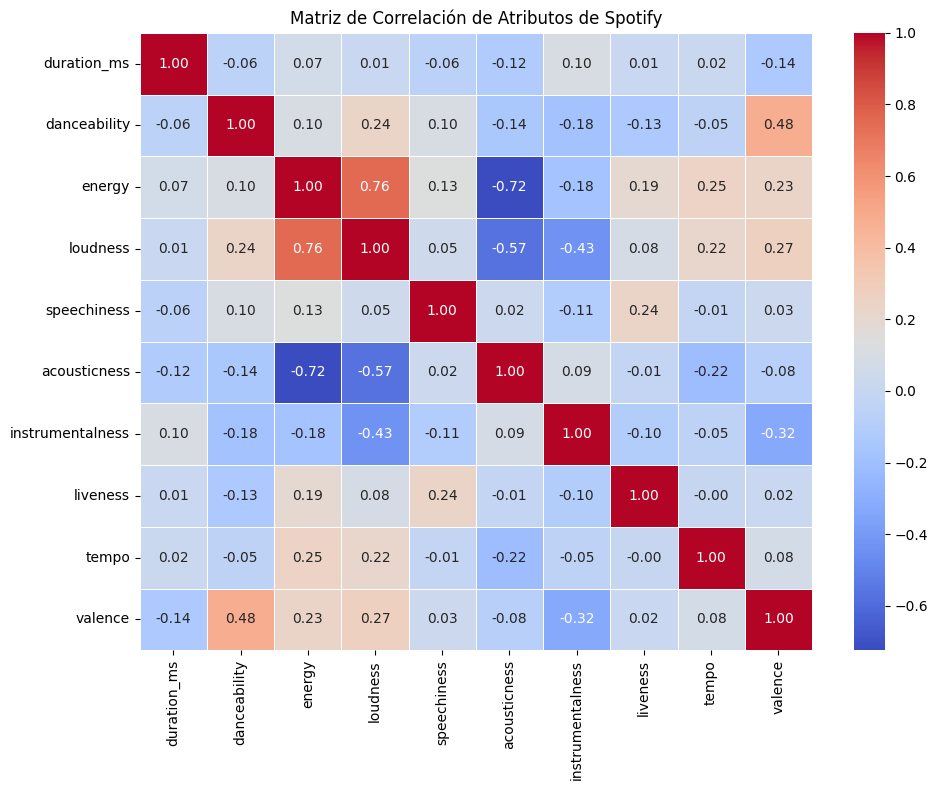

In [10]:


plt.figure(figsize=(10, 8))
sns.heatmap(df_train[predictorias].corr(), annot=True, cmap='coolwarm', fmt=".2f", linewidths=0.5)
plt.title('Matriz de Correlación de Atributos de Spotify')
plt.tight_layout()
plt.show()

### 1.A.2 Entrenamiento de las tres versiones (10, 5 y 3 variables)

El intercepto es el valor de $\theta_0$.

Los coeficiontes $\theta_n$ son los coeficientes de cada variable predictoria.

In [11]:
configs = {
    'complete': predictorias,
    'reduce' : listFive,
    'min': listThree
}

X = df_train[predictorias]
y = df_train['popularity']

scaler = StandardScaler()

X = scaler.fit_transform(X, y)

# 2. Instanciar y entrenar el modelo de Regresión Lineal
modelo = LinearRegression() 
modelo.fit(X, y)


print(f"Intercepto : {modelo.intercept_:.4f}\n")

# 4. Crear una tabla (DataFrame) para asociar cada variable con su coeficiente
df_parametros = pd.DataFrame({
    'Variable': predictorias,
    'Coeficiente': modelo.coef_
}).sort_values(by='Coeficiente', ascending=False)

display(df_parametros)


Intercepto : 37.1160



,Variable,Coeficiente
1,danceability,1.605131
3,loudness,1.101094
8,tempo,-0.186671
5,acousticness,-0.329119
7,liveness,-0.393358
0,duration_ms,-0.972467
2,energy,-1.610351
4,speechiness,-1.900636
9,valence,-2.055945
6,instrumentalness,-3.813136


Esos coeficientes son cada uno de los $\theta$ de las variables predictorias. 



La función de costos es: 
$J(\theta) =  \frac{1}{2m}\sum_{i=1}^m ( h\theta^{(x^{(i)})} − y^{(i)} )2$


La ecuación normal: $\hat{\theta} = (X^T X)^{-1} X^T y$


In [12]:
X_b = add_dummy_feature(X)
theta_best = np.linalg.inv(X_b.T @ X_b) @ X_b.T @ y

print(theta_best)

[37.11599344 -0.97246748  1.60513089 -1.61035089  1.10109376 -1.90063613
 -0.32911894 -3.81313587 -0.39335787 -0.1866713  -2.05594509]


### 1.A.3 Comparación en entrenamiento y validación

_Métricas apropiadas: RMSE, MAE, R²._

$\mathrm{RMSE}(\mathbf{X},h)=\sqrt{\frac{1}{m}\sum_{i=1}^{m}\bigl(h(\mathbf{x}^{(i)})-y^{(i)}\bigr)^{2}}$

$\mathrm{MSE}(\mathbf{X},h_{\boldsymbol{\theta}})=\frac{1}{m}\sum_{i=1}^{m}\bigl(\boldsymbol{\theta}^{\!\top}\mathbf{x}^{(i)}-y^{(i)}\bigr)^{2}$

**Para el equipo.** Comparen la mejora respecto a la media, las brechas entre entrenamiento y validación y el costo de reducir de 10 a 5 y de 5 a 3 variables.

In [13]:
models = {}
results = []

X = df_train[predictorias]
y1_train = df_train['popularity']
y1_val   = df_val['popularity']


for config, cols in configs.items():
    pipe = make_pipeline(StandardScaler(), LinearRegression())
    pipe.fit(df_train[cols], y1_train)
    models[config] = pipe


    pred_train = pipe.predict(df_train[cols])
    pred_val = pipe.predict(df_val[cols])

    results.append({
        "version": config,
        "n_vars": len(cols),
        "R2_train": r2_score(y1_train, pred_train),
        "R2_val": r2_score(y1_val, pred_val),
        "RMSE_train": np.sqrt(mean_squared_error(y1_train, pred_train)),
        "RMSE_val": np.sqrt(mean_squared_error(y1_val, pred_val)),
        "MAE_train": mean_absolute_error(y1_train, pred_train),  
        "MAE_val": mean_absolute_error(y1_val, pred_val) 
    })


table = pd.DataFrame(results)
display(table)

,version,n_vars,R2_train,R2_val,RMSE_train,RMSE_val,MAE_train,MAE_val
0,complete,10,0.069231,0.063661,17.500183,17.580138,14.375249,14.457106
1,reduce,5,0.054217,0.052301,17.640760,17.686465,14.600123,14.670524
2,min,3,0.051832,0.051261,17.662994,17.696167,14.610081,14.682621


RMSE en validación al predecir la media de entrenamiento: 18.1680


,version,n_vars,brecha_R2_train_val,mejora_RMSE_vs_media_pct,RMSE_sobre_MAE_val,caida_R2_val_al_reducir
0,complete,10,0.005570,3.235733,1.216021,NaN
1,reduce,5,0.001916,2.650493,1.205578,0.01136
2,min,3,0.000571,2.597090,1.205246,0.00104


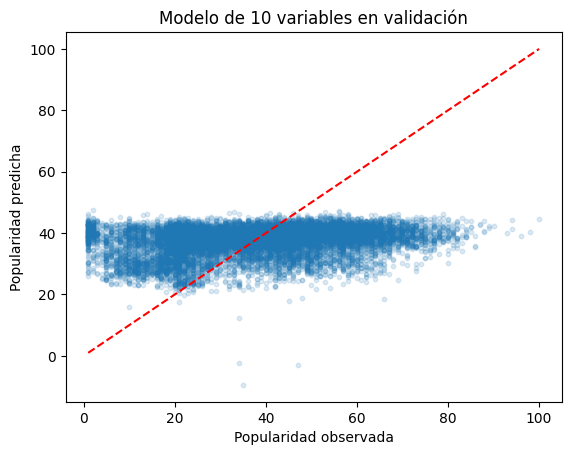

In [14]:
# Referencia constante ajustada solo en entrenamiento.
pred_media = np.full(len(y1_val), y1_train.mean())
rmse_media = np.sqrt(mean_squared_error(y1_val, pred_media))
comparacion = table[["version", "n_vars"]].copy()
comparacion["brecha_R2_train_val"] = table["R2_train"] - table["R2_val"]
comparacion["mejora_RMSE_vs_media_pct"] = 100 * (1 - table["RMSE_val"] / rmse_media)
comparacion["RMSE_sobre_MAE_val"] = table["RMSE_val"] / table["MAE_val"]
comparacion["caida_R2_val_al_reducir"] = -table["R2_val"].diff()
np.testing.assert_allclose(table["R2_val"], 1 - table["RMSE_val"]**2 / y1_val.var(ddof=0))
print(f"RMSE en validación al predecir la media de entrenamiento: {rmse_media:.4f}")
display(comparacion)

pred_completo = models["complete"].predict(df_val[predictorias])
plt.scatter(y1_val, pred_completo, s=10, alpha=0.15)
plt.plot([y1_val.min(), y1_val.max()], [y1_val.min(), y1_val.max()], "r--")
plt.xlabel("Popularidad observada")
plt.ylabel("Popularidad predicha")
plt.title("Modelo de 10 variables en validación")
plt.show()

### 1.A.4 Evaluación en prueba de las dos mejores versiones (según validación)

Se seleccionan las dos versiones con mayor R² de validación.

In [15]:
mejores_y1 = table.nlargest(2, "R2_val")["version"]
y1_test = df_test["popularity"]
prueba_y1 = []
for nombre in mejores_y1:
    columnas = configs[nombre]
    pred = models[nombre].predict(df_test[columnas])
    prueba_y1.append({
        "version": nombre, "n_vars": len(columnas),
        "R2_test": r2_score(y1_test, pred),
        "RMSE_test": np.sqrt(mean_squared_error(y1_test, pred)),
        "MAE_test": mean_absolute_error(y1_test, pred),
    })
display(pd.DataFrame(prueba_y1))

,version,n_vars,R2_test,RMSE_test,MAE_test
0,complete,10,0.074063,17.405252,14.292572
1,reduce,5,0.057681,17.558546,14.550657


## Pregunta 1.B — Regresión logística (Y2 binaria)

### 1.B.1 Selección de variables (solo con datos de entrenamiento)

El equipo eligió la información mutua con `explicit`. El ranking se calcula sobre entrenamiento y sus primeras cinco y tres posiciones definen los subconjuntos. Para la selección posterior se usará el ROC-AUC de validación.

In [16]:
y2_train = df_train["explicit"]
y2_val = df_val["explicit"]
X2_train = df_train[predictorias]
puntajes = mutual_info_classif(X2_train, y2_train, random_state=seed)
ranking_y2 = pd.Series(puntajes, index=predictorias).sort_values(ascending=False, kind="stable")
display(ranking_y2.rename("Información mutua en entrenamiento"))

lista_5_y2 = ranking_y2.head(5).index.tolist()
lista_3_y2 = ranking_y2.head(3).index.tolist()
assert set(lista_3_y2) < set(lista_5_y2) < set(predictorias)
configs_y2 = {"complete": predictorias, "reduce": lista_5_y2, "min": lista_3_y2}
print("5 variables:", ", ".join(lista_5_y2))
print("3 variables:", ", ".join(lista_3_y2))

speechiness         0.046522
instrumentalness    0.012128
duration_ms         0.011801
loudness            0.010403
energy              0.009634
tempo               0.009247
acousticness        0.008883
danceability        0.006814
liveness            0.004116
valence             0.003074
Name: Información mutua en entrenamiento, dtype: float64

5 variables: speechiness, instrumentalness, duration_ms, loudness, energy
3 variables: speechiness, instrumentalness, duration_ms


### 1.B.2 Entrenamiento de las tres versiones (10, 5 y 3 variables)

In [17]:
modelos_y2 = {}
for nombre, columnas in configs_y2.items():
    pipe = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000, random_state=seed))
    modelos_y2[nombre] = pipe.fit(df_train[columnas], y2_train)

### 1.B.3 Comparación en entrenamiento y validación

_Métricas apropiadas: accuracy, precision, recall, F1, ROC-AUC, matriz de confusión._

**Para el equipo.** Justifiquen la métrica elegida con la proporción de canciones explícitas y los errores de la matriz de confusión.

In [18]:
def metricas_y2(modelo, datos, columnas):
    reales = datos["explicit"]
    clases = modelo.predict(datos[columnas])
    proba = modelo.predict_proba(datos[columnas])[:, 1]
    return {
        "accuracy": accuracy_score(reales, clases),
        "precision": precision_score(reales, clases, zero_division=0),
        "recall": recall_score(reales, clases, zero_division=0),
        "F1": f1_score(reales, clases, zero_division=0),
        "ROC_AUC": roc_auc_score(reales, proba),
    }

resultados_y2 = []
for nombre, modelo_y2 in modelos_y2.items():
    for particion, datos in [("train", df_train), ("val", df_val)]:
        columnas = configs_y2[nombre]
        resultados_y2.append({"version": nombre, "particion": particion, "n_vars": len(columnas),
                              **metricas_y2(modelo_y2, datos, columnas)})
tabla_y2 = pd.DataFrame(resultados_y2)
display(tabla_y2)
clase_mayoritaria = y2_train.mode().iat[0]
print("Proporción por clase en validación:")
display(y2_val.value_counts(normalize=True).sort_index())
print(f"Accuracy de predecir siempre la clase {clase_mayoritaria}: "
      f"{(y2_val == clase_mayoritaria).mean():.4f}")

validacion_y2 = tabla_y2.loc[tabla_y2["particion"] == "val"]
mejores_y2 = validacion_y2.nlargest(2, "ROC_AUC")["version"].tolist()
mejor = mejores_y2[0]
pred_val = modelos_y2[mejor].predict(df_val[configs_y2[mejor]])
print(f"Matriz de confusión en validación: {mejor}")
display(pd.DataFrame(confusion_matrix(y2_val, pred_val, labels=[0, 1]),
                     index=["Real 0", "Real 1"], columns=["Predicho 0", "Predicho 1"]))

,version,particion,n_vars,accuracy,precision,recall,F1,ROC_AUC
0,complete,train,10,0.913758,0.522037,0.109154,0.180556,0.818150
1,complete,val,10,0.916479,0.560000,0.108949,0.182410,0.821495
2,reduce,train,5,0.914489,0.556728,0.086422,0.149619,0.789550
3,reduce,val,5,0.916729,0.595745,0.081712,0.143713,0.799291
4,min,train,3,0.914667,0.565934,0.084374,0.146854,0.782999
5,min,val,3,0.916064,0.571429,0.073930,0.130922,0.789574


Proporción por clase en validación:


explicit
0    0.914483
1    0.085517
Name: proportion, dtype: float64

Accuracy de predecir siempre la clase 0: 0.9145
Matriz de confusión en validación: complete


,Predicho 0,Predicho 1
Real 0,10905,88
Real 1,916,112


### 1.B.4 Evaluación en prueba de las dos mejores versiones (según validación)

In [19]:
prueba_y2 = []
for nombre in mejores_y2:
    columnas = configs_y2[nombre]
    prueba_y2.append({"version": nombre, "n_vars": len(columnas),
                      **metricas_y2(modelos_y2[nombre], df_test, columnas)})
display(pd.DataFrame(prueba_y2))

,version,n_vars,accuracy,precision,recall,F1,ROC_AUC
0,complete,10,0.917311,0.566038,0.117417,0.194489,0.799335
1,reduce,5,0.917894,0.607362,0.096869,0.167089,0.772634


## 1.C — Análisis final de la Pregunta 1

_Influencia de la cantidad de variables predictoras en el desempeño y la generalización; discusión de overfitting / underfitting (curvas de aprendizaje, brecha train vs. validación)._

**Redacción del equipo.** Usen los resultados para explicar cómo varía el desempeño con el número de variables, qué evidencia encuentran sobre generalización en cada tarea y qué limitaciones tiene la comparación.

## Declaración de uso de herramientas generativas

Se utilizó Codex para separar la Pregunta 1, corregir la ejecución y trasladar a celdas los cálculos descritos en la guía. La elección de criterios y la interpretación de los resultados corresponden al equipo.